# Composite analysis for NoRad and Rad

## Import packages

In [61]:
import sys
import h5py
import numpy as np

from typing import cast
from pathlib import Path

from matplotlib import pyplot as plt

sys.path.append("/home/b11209013/Kuang-python/src")
from API import MeanState
from Configuration.Params import Constant

style_path = Path("/home/b11209013/Kuang-python/v0.1.0_Analysis/scientific.mplstyle")

plt.style.use(style_path)

## Configure the experiments

In [62]:
data_path: Path = Path("/work/b11209013/Kuang-python/v0.1.0/two-way/Eastward")
EXPS: list[str] = ["NoRad", "Rad"]
FILES: list[str] = ["2026-10-28-07-25-19-242016551-4092283", "2026-10-28-08-37-05-996147668-3800833"]

# Process both experiments; use EXPS[:1] for NoRad alone.
active_exps: list[str] = EXPS[:]
run_paths: dict[str, Path] = {exp: data_path / exp / run for exp, run in zip(EXPS, FILES)}

# Exclude the first 20 days, as in the reference composite.
skip_days: float = 20.0

## Heating-centered composite method

Prepare fields separately with axes `(ensemble, time, x, z)` or `(ensemble, time, x)`
for column quantities. The composite uses total column heating to align all
variables at each ensemble/time pair, then averages over members and times
at or after `skip_days`. Each result has shape `(x, z)` or `(x,)`.

The helper accumulates one snapshot at a time and ignores NaNs at each grid point.
Loading and auxiliary calculations remain separate from compositing.

In [63]:
def heating_centered_composite(field, shifts, time_indices, second_field=None):
    """Composite (ensemble, time, x[, z]) data using heating-based x shifts."""
    if field.ndim not in (3, 4):
        raise ValueError("Expected field axes (ensemble, time, x) or (ensemble, time, x, z).")
    if shifts.shape != (field.shape[0], len(time_indices)):
        raise ValueError("Provide one shift for each retained ensemble/time pair.")
    if second_field is not None and second_field.shape != field.shape:
        raise ValueError("The two modal fields must have matching shapes.")
    
    total = np.zeros(field.shape[2:], dtype=np.result_type(field.dtype, np.float64))
    count = np.zeros(field.shape[2:], dtype=np.int64)
    for ne in range(field.shape[0]):
        for jt, it in enumerate(time_indices):
            snapshot = field[ne, it]
            if second_field is not None:
                snapshot = snapshot + second_field[ne, it]
            centered = np.roll(snapshot, int(shifts[ne, jt]), axis=0)
            valid = ~np.isnan(centered)
            total += np.where(valid, centered, 0)
            count += valid
    composite = np.full(total.shape, np.nan, dtype=total.dtype)
    np.divide(total, count, out=composite, where=count > 0)
    return composite

## Prepare loading and composite functions

`load_data` reads the run once. After calculating auxiliary quantities, pass the
prepared variable dictionary to `composite_experiment`. It does no file I/O and
does not modify its inputs. `composite_results[exp]` retains coordinates and
centering diagnostics alongside the computed fields.

### Load data function

In [64]:
def load_data(run_path: Path) -> tuple[dict[str, np.ndarray], ...]:
    # Load Galerkin State
    with h5py.File(run_path / "GalerkinState.h5", "r") as f:
        x: np.ndarray = cast(h5py.Dataset, f["x"])[:]
        z: np.ndarray = cast(h5py.Dataset, f["z"])[:]
        t: np.ndarray = cast(h5py.Dataset, f["time"])[:]

        data: dict[str, np.ndarray] = {
            key: cast(h5py.Dataset, f[key])[...]
            for key in ["w1", "w2", "T1", "T2", "J1", "J2"]
        } # shape: (ensemble, time, zonal, level)

    nens, nt, nx, nz = data["w1"].shape

    return {"x": x, "z": z, "t": t}, data

### Functions for composite

In [65]:
def composite_experiment(
    experiment: str,
    fields: dict[str, np.ndarray],
    coordinates: dict[str, np.ndarray],
    skip_days: float = 20.0,
    *,
    column_heating: np.ndarray | None = None,
):
    """Composite supplied fields using a common heating-based alignment.

    fields: named arrays with axes (ensemble, time, x[, z]). All supplied
        variables, including derived quantities such as N2, are composited.
    coordinates: x, z, and t arrays from load_data.
    column_heating: optional (ensemble, time, x) centering proxy. When omitted,
        vertically average fields['J'], or fields['J1'] + fields['J2'], using
        the existing trapezoidal formula. Supply this proxy when compositing
        a subset that does not contain the heating fields.

    Missing total J, w, and T fields are added when both modal fields exist.
    Explicitly supplied totals take precedence. Inputs are never modified.
    """
    if not fields:
        raise ValueError("Provide at least one field to composite.")
    x, z, t = (np.asarray(coordinates[key]) for key in ("x", "z", "t"))
    if any(coord.ndim != 1 or coord.size == 0 for coord in (x, z, t)):
        raise ValueError("Coordinates x, z, and t must be nonempty one-dimensional arrays.")
    first_field = next(iter(fields.values()))
    if first_field.ndim not in (3, 4):
        raise ValueError("Expected field axes (ensemble, time, x[, z]).")
    nens = first_field.shape[0]
    expected_shape = (nens, t.size, x.size)
    for name, values in fields.items():
        if values.ndim not in (3, 4) or values.shape[:3] != expected_shape:
            raise ValueError(f"{name}: expected leading axes {expected_shape} (ensemble, time, x).")
        if values.ndim == 4 and values.shape[-1] != z.size:
            raise ValueError(f"{name}: vertical axis must match z ({z.size} levels).")

    composite_time_indices = np.flatnonzero(t >= skip_days)
    if nens == 0 or composite_time_indices.size == 0:
        raise ValueError("The composite requires at least one member and one retained time.")

    if column_heating is None:
        if "J" in fields:
            Qc = fields["J"]
        elif "J1" in fields and "J2" in fields:
            Qc = fields["J1"] + fields["J2"]
        else:
            raise ValueError("Supply column_heating, J, or both J1 and J2 for centering.")
        if Qc.ndim != 4:
            raise ValueError("Heating J must include the vertical axis; pass column_heating for a column field.")
        # Preserve the existing vertically integrated heating divided by depth.
        Qc_column: np.ndarray = np.trapz(Qc, z, axis=-1) / np.trapz(np.ones_like(z), z, axis=-1)
    else:
        Qc_column = np.asarray(column_heating)
    if Qc_column.shape != expected_shape:
        raise ValueError(f"column_heating must have shape {expected_shape} (ensemble, time, x).")

    print(f"{experiment}: compositing {nens} members and {composite_time_indices.size} times "
          f"from {t[composite_time_indices[0]]:g} to {t[composite_time_indices[-1]]:g} days.")
    x_center_idx: np.intp = np.argmin(np.abs(x))
    Qc_column_selected = Qc_column[:, composite_time_indices, :]
    if np.any(np.all(np.isnan(Qc_column_selected), axis=-1)):
        raise ValueError("Cannot locate a heating maximum in an all-NaN column profile.")
    # nanargmax selects the first maximum if periodic peaks tie.
    shifts = x_center_idx - np.nanargmax(Qc_column_selected, axis=-1)
    Qc_column_rolled = np.empty_like(Qc_column_selected)
    for ne in range(nens):
        for jt in range(composite_time_indices.size):
            Qc_column_rolled[ne, jt] = np.roll(
                Qc_column_selected[ne, jt], int(shifts[ne, jt]), axis=0,
            )
    Qc_column_composite = np.nanmean(Qc_column_rolled, axis=(0, 1))

    composite = {
        name: heating_centered_composite(values, shifts, composite_time_indices)
        for name, values in fields.items()
    }
    for name in ("J", "w", "T"):
        if name not in fields and f"{name}1" in fields and f"{name}2" in fields:
            composite[name] = heating_centered_composite(
                fields[f"{name}1"], shifts, composite_time_indices,
                second_field=fields[f"{name}2"],
            )
    print(f"{experiment} composite field shapes:", {name: values.shape for name, values in composite.items()})

    return {
        "fields": composite,
        "x": x,
        "z": z,
        "time": t[composite_time_indices],
        "x_relative": x - x[x_center_idx],
        "nens": nens,
        "shifts": shifts,
        "column_composite": Qc_column_composite,
        "column_first_time": Qc_column_rolled[:, 0, :].copy(),
    }

### Load different experiments

In [66]:
# Check both inputs before starting the expensive loading and integration.
for exp in active_exps:
    source_path = run_paths[exp] / "GalerkinState.h5"
    if not source_path.is_file():
        raise FileNotFoundError(f"{exp}: missing {source_path}")
    with h5py.File(source_path, "r") as f:
        if not f.attrs.get("complete", False):
            raise ValueError(f"{exp}: Galerkin reconstruction is incomplete.")

data  : dict[str, dict[str, np.ndarray]] = {}
coords: dict[str, dict[str, np.ndarray]] = {}

for exp in active_exps:
    coords[exp], data[exp] = load_data(run_paths[exp])


## Calculate auxiliary quantities

### Combining mean state with perturbation fields

In [67]:
# Load mean state variables
mean_state: MeanState = MeanState()
const     : Constant = Constant()
p_mean    : np.ndarray = mean_state.pmean()
t_mean    : np.ndarray = mean_state.Tmean()

# combining mean state with experiment data
tot_temp: dict[str, np.ndarray] = {
    exp: t_mean + data[exp]["T1"] + data[exp]["T2"]
    for exp in active_exps
}

tot_press: dict[str, np.ndarray] = {
    exp: const.p0 * np.exp(-const.g/const.R * np.cumsum(1/tot_temp[exp]*np.diff(coords[exp]["z"], prepend=0), axis=-1))
    for exp in active_exps
}

# calculate total potential temperature
tot_pot_temp: dict[str, np.ndarray] = {
    exp: tot_temp[exp] * (const.p0 / tot_press[exp])**(const.R/const.cp)
    for exp in active_exps
}

### Calculate Brunt-Väisälä frequency

In [68]:
N2: dict[str, np.ndarray] = {
    exp: const.g / tot_pot_temp[exp] * np.gradient(tot_pot_temp[exp], coords[exp]["z"], axis=-1)
    for exp in active_exps
}

N2_anom: dict[str, np.ndarray] = {
    exp: N2[exp] - N2[exp].mean(axis=(1, 2), keepdims=True)
    for exp in active_exps
}

for exp in active_exps:
    data[exp]["N2"] = N2[exp]
    data[exp]["N2_anom"] = N2_anom[exp]

## Composite analysis of the prepared variables

Pass `data[exp]` to composite every prepared variable, including `N2`. The
returned structure is unchanged, so the plotting cells can continue to use
`composite_results[exp]["fields"]`.

To composite only a custom field using the same alignment:

```python
exp = "NoRad"
Qc = data[exp]["J1"] + data[exp]["J2"]
z = coords[exp]["z"]
column_heating = np.trapz(Qc, z, axis=-1) / np.trapz(np.ones_like(z), z, axis=-1)
n2_result = composite_experiment(
    exp, {"N2": N2[exp]}, coords[exp], skip_days,
    column_heating=column_heating,
)
```

The custom field must retain the original ensemble/time order and spatial grid.
Column variables with shape `(ensemble, time, x)` are also supported.

In [69]:
composite_results = {}
for exp in active_exps:
    composite_results[exp] = composite_experiment(
        experiment=exp,
        fields=data[exp],
        coordinates=coords[exp],
        skip_days=skip_days,
    )

composites = {exp: result["fields"] for exp, result in composite_results.items()}


NoRad: compositing 90 members and 20 times from 20.375 to 39.375 days.
NoRad composite field shapes: {'w1': (401, 71), 'w2': (401, 71), 'T1': (401, 71), 'T2': (401, 71), 'J1': (401, 71), 'J2': (401, 71), 'N2': (401, 71), 'N2_anom': (401, 71), 'J': (401, 71), 'w': (401, 71), 'T': (401, 71)}
Rad: compositing 90 members and 20 times from 20.375 to 39.375 days.
Rad composite field shapes: {'w1': (401, 71), 'w2': (401, 71), 'T1': (401, 71), 'T2': (401, 71), 'J1': (401, 71), 'J2': (401, 71), 'N2': (401, 71), 'N2_anom': (401, 71), 'J': (401, 71), 'w': (401, 71), 'T': (401, 71)}


## Compare the composite fields

For the selected experiment, show J with w contours, J with T contours, and
a smaller N2 anomaly panel underneath. All three panels share relative
longitude. The N2 anomaly panel retains the vertical structure from the surface
to 3000 m (3 km), with a separate color scale centered on zero. It displays
spatial variation in the time/ensemble composite, not a time series.


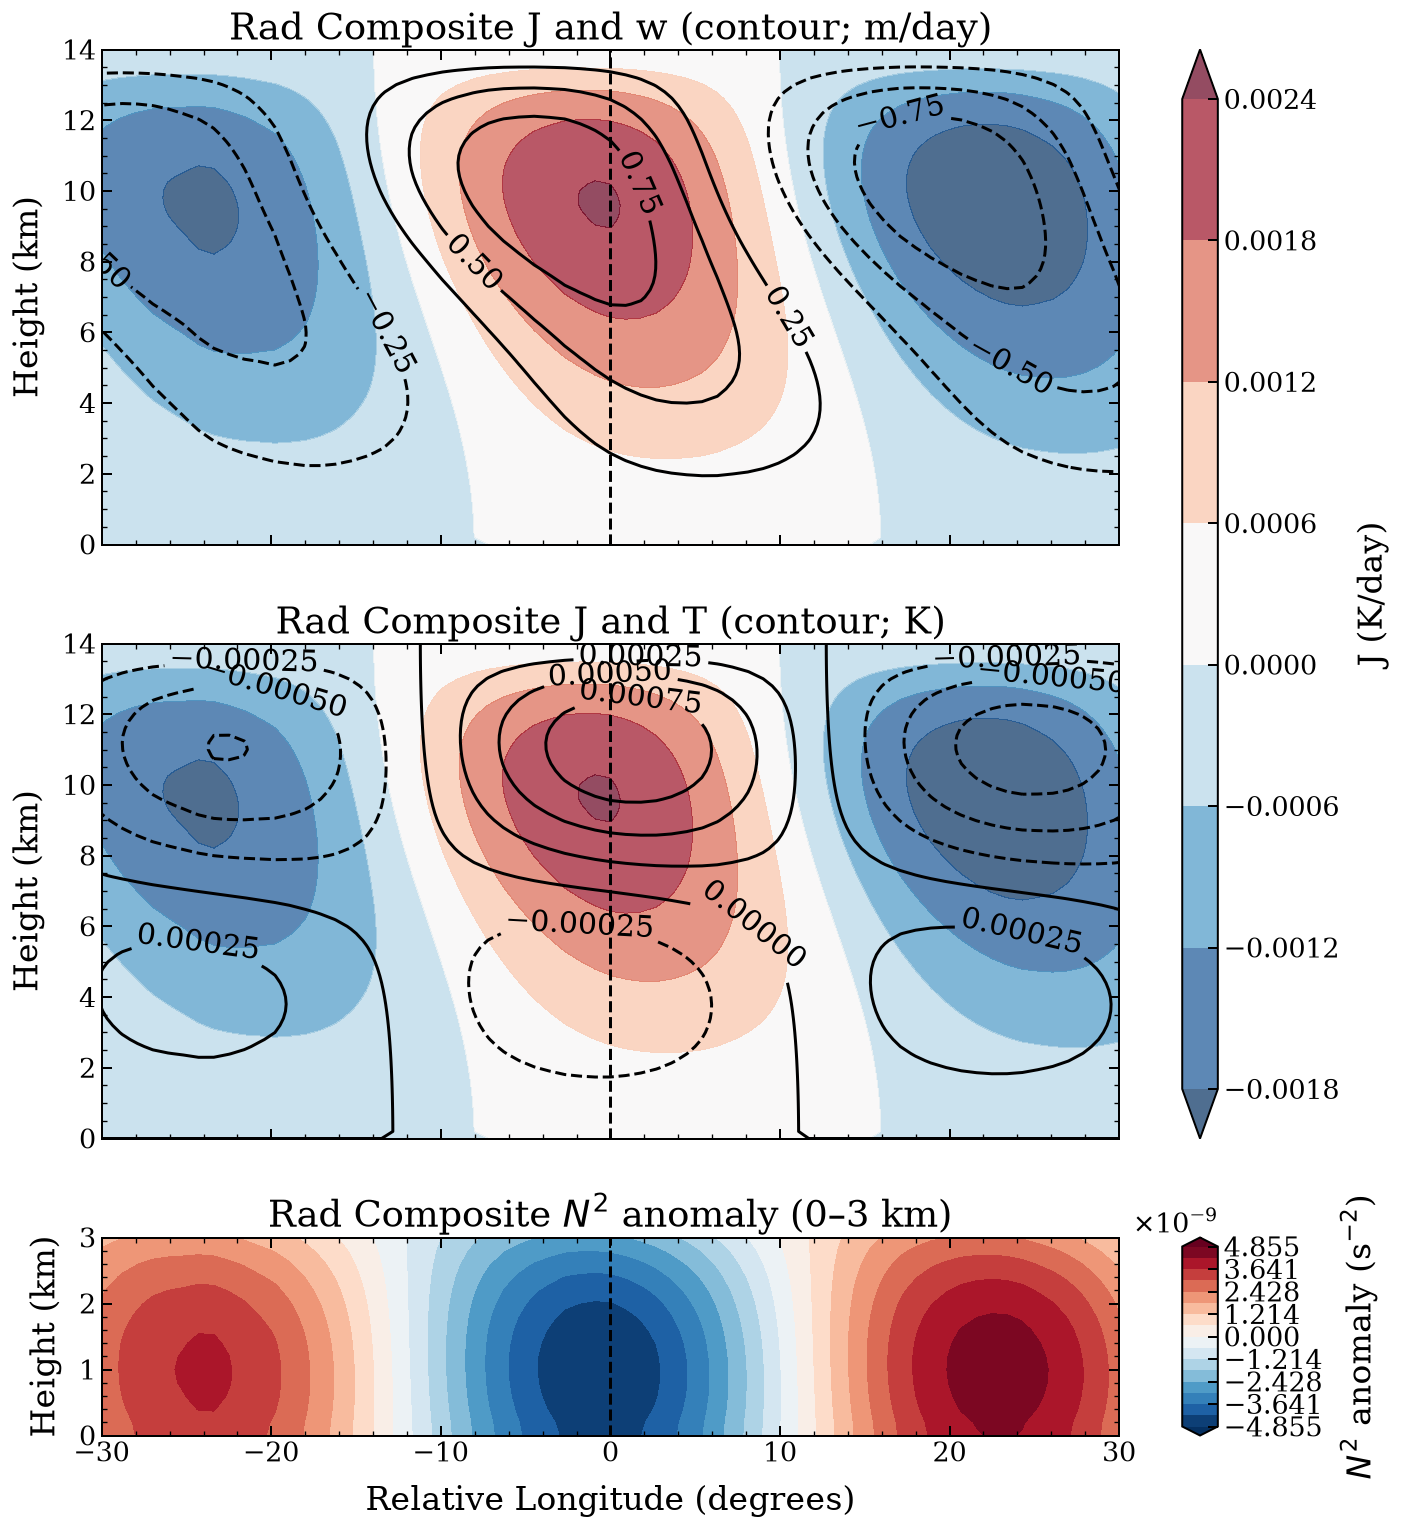

In [72]:
metres_per_degree = 2 * np.pi * 6.371e6 / 360.0
exp: str = "Rad"
n2_max_height_m: float = 3000.0

# Use the selected experiment's own coordinates and prepared composite fields.
result = composite_results[exp]
longitude = result["x_relative"] / metres_per_degree
height_m = result["z"]
z = height_m / 1000.0
fields = result["fields"]
low_levels = (height_m >= 0.0) & (height_m <= n2_max_height_m)
if np.count_nonzero(low_levels) < 2:
    raise ValueError("The N2 anomaly panel requires at least two levels below 3 km.")

# Find the maximum of temperature and vertical motion.
w_max = np.round(np.max(np.abs(fields["w"])), decimals=0)
T_max = np.round(np.max(np.abs(fields["T"])), decimals=4)

# A dedicated colorbar column keeps all three longitude axes aligned.
fig = plt.figure(figsize=(12, 15))
grid = fig.add_gridspec(
    3, 2, height_ratios=[3, 3, 1.2], width_ratios=[1, 0.035],
    hspace=0.25, wspace=0.12,
)
ax1 = fig.add_subplot(grid[0, 0])
ax2 = fig.add_subplot(grid[1, 0], sharex=ax1)
ax3 = fig.add_subplot(grid[2, 0], sharex=ax1)
cax = fig.add_subplot(grid[:2, 1])
n2_cax = fig.add_subplot(grid[2, 1])

norad_J_ctf = ax1.contourf(
    longitude, z, fields["J"].T,
    cmap="RdBu_r", extend="both", alpha=0.7,
)
norad_w_ctf = ax1.contour(
    longitude, z, fields["w"].T,
    colors="k", linewidths=1.8,
    levels=[i for i in np.arange(-w_max, w_max, w_max/4) if np.abs(i) >= 0.1],
)
ax1.set(
    ylabel="Height (km)", xlim=(-30, 30), ylim=(0, np.max(z)),
    title=f"{exp} Composite J and w (contour; m/day)",
)
ax1.axvline(0.0, color="k", linewidth=1.8, linestyle="--")
ax1.clabel(norad_w_ctf, fontsize=18)
ax1.tick_params(labelbottom=False)

norad_J_ctf = ax2.contourf(
    longitude, z, fields["J"].T,
    cmap="RdBu_r", extend="both", alpha=0.7,
)
norad_T_ctf = ax2.contour(
    longitude, z, fields["T"].T,
    colors="k", linewidths=1.8,
    levels=[i for i in np.arange(-T_max, T_max, T_max/4)],
)
ax2.axvline(0.0, color="k", linewidth=1.8, linestyle="--")
ax2.set(
    ylabel="Height (km)", xlim=(-30, 30), ylim=(0, np.max(z)),
    title=f"{exp} Composite J and T (contour; K)",
)
ax2.clabel(norad_T_ctf, fontsize=18)
ax2.tick_params(labelbottom=False)
fig.colorbar(norad_J_ctf, cax=cax, label="J (K/day)")

# Keep only the lower 3 km, with a symmetric anomaly scale in the visible domain.
n2_low = fields["N2_anom"][:, low_levels].T
visible = np.abs(longitude) <= 30.0
n2_limit = float(np.nanmax(np.abs(n2_low[:, visible])))
if not np.isfinite(n2_limit):
    raise ValueError("N2_anom has no finite values in the plotted lower-tropospheric region.")
n2_limit = n2_limit or 1e-12
n2_ctf = ax3.contourf(
    longitude, z[low_levels], n2_low,
    levels=np.linspace(-n2_limit, n2_limit, 17), cmap="RdBu_r", extend="both",
)
ax3.axvline(0.0, color="k", linewidth=1.8, linestyle="--")
ax3.set(
    xlabel="Relative Longitude (degrees)", ylabel="Height (km)",
    xlim=(-30, 30), ylim=(0, n2_max_height_m / 1000.0),
    title=rf"{exp} Composite $N^2$ anomaly (0–3 km)",
)
n2_colorbar = fig.colorbar(n2_ctf, cax=n2_cax, label=r"$N^2$ anomaly (s$^{-2}$)")
n2_colorbar.ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

plt.savefig(f"/home/b11209013/Kuang-python/v0.1.0_Analysis/Figure/{exp}_composite_J_w_T.png", bbox_inches="tight")
plt.show()
